# Pergunta de pesquisa 1
---

Qual é a taxa de acerto ($Pass@1$, $T=0$) das LLMs na resolução textual dos problemas da OBI (Nível Sênior) e como esse desempenho varia entre as 5 linguagens de programação avaliadas (Python, C++, C, Java e JavaScript)?

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import json
from codebleu import calc_codebleu

In [15]:
questions_path = []

path_database = Path('../database/dataset_obi_senior/')

for path_question in sorted(path_database.glob("*")):
    if path_question.is_dir():
        questions_path.append(path_question)
        print(path_question.name)

problems = []

for question_path in questions_path:
    problems.append(json.loads(Path(question_path / "problem.json").read_text(encoding="utf-8")))

A idade de Dona Mônica
Acelerador de partículas
Alfabeto Alienígena
Aplicativo de calorias
Arara!
Arco e flecha
Arranha-céu
Baralho
Barcos da Nlogônia
Bingo!
Botas Trocadas
Brigadeiros
Burocracia
Cafeteria
Calçada Imperial
Camisetas da Olimpíada
Candidatas
Caravana
Carrinho
Chaves
Chuva
Chuva_2019
Chuva_2022
Ciclovias
Computador
Concurso
Construtora
Construção de Rodovia
Contas a pagar
Cortando o Papel
Cubo Preto
Código
Dança de Formatura
Dario e Xerxes
Direção
Dividindo o império
Divisão do Tesouro
Dona Formiga
Dona Minhoca
Dona Minhoca_2022
Dupla de tênis
Dígitos
Emoticons
Energia
Escadaria
Estoque
Estrada
Etiquetas
Falha de segurança
Fast-Food
Feira de Artesanato
Festa Junina
Festa olímpica
Fila
Fissura Perigosa
Fotografia
Fotos de Relíquias
Frete
Game Show
Game-10
Garamana
Grupos de Trabalho
Gráfico de Barras
Harmonia Nasal
Hidrovias e Rodovias
Hotel
Intervalo Distinto
Irmãos
Jardim de infância
Jogo da Vida
Jogo de Pratos
Jogo do Poder
Jogo do Preto e Branco
Lista palíndroma
Lâmpad

In [16]:
models_fs = [
    "deepseek_deepseek-v4.1-flash",
    "gemini-3.8-flash",
    "openai_gpt-6-luna",
    "z-ai_glm-5.3-flash"
]
languages_fs = ["python", "cpp", "c", "java", "javascript"]
missing_count = 0

for question_path in questions_path:
    for lang in languages_fs:
        for m in models_fs:
            code_path = Path(f"../results/dataset_obi_senior/{m}/zero_shot/{lang}/text/{question_path.name}.json")
            if not code_path.exists():
                print(f"[{m} - {lang}]: {question_path.name}")
                missing_count += 1

if missing_count == 0:
    print("Verificando arquivos gerados pelas LLMs...")
    print("Todos os arquivos JSON de código existem para todos os modelos e linguagens!")

Verificando arquivos gerados pelas LLMs...
Todos os arquivos JSON de código existem para todos os modelos e linguagens!


In [17]:
count_dificulty = {}

df_problems = pd.DataFrame(problems)

for level in df_problems["level"].unique():
    cases = df_problems[df_problems["level"] == level]
    count_dificulty[level] = len(cases)

In [18]:
print(count_dificulty)

{'senior': 125}


In [19]:
def read_csv(path: Path) -> pd.DataFrame:
    try:
        return pd.read_csv(path)
    except:
        return None

In [20]:
languages = ["Python", "C++", "C", "Java", "JavaScript"]
TOTAL_PROBLEMS = 125
verdicts = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

def count_ac_by_language(data: pd.DataFrame, languages: list, problems_per_lang: int = 125) -> dict:
    counts = {}
    for i, lang in enumerate(languages):
        sub_df = data.iloc[i * problems_per_lang : (i + 1) * problems_per_lang]
        ac = (sub_df["judge_predict"] == "AC").sum()
        counts[lang] = int(ac)
    counts["Média"] = float(np.mean([counts[l] for l in languages]))
    counts["Total"] = int(sum(counts[l] for l in languages))
    return counts

In [21]:
model_paths = {
    "DeepSeek v4.1 Flash": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash.csv"),
    "Gemini 3.8 Flash": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash.csv"),
    "GPT-6 Luna": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna.csv"),
    "GLM 5.3 Flash": Path("../results/dataset_obi_senior/judge/z-ai_glm-5.3-flash.csv")
}

datas = {}
results = {}

for name, path in model_paths.items():
    df = read_csv(path)
    if df is not None:
        # Identifica a linguagem em cada bloco de 125 linhas
        df["language"] = [languages[i // TOTAL_PROBLEMS] for i in range(len(df))]
        datas[name] = df
        results[name] = count_ac_by_language(df, languages, TOTAL_PROBLEMS)

In [22]:
for name, data in datas.items():
    print(f"{name}: {len(data)} linhas ({len(data) // TOTAL_PROBLEMS} linguagens x {TOTAL_PROBLEMS} problemas)")
    names_in_csv = set(data["question_name"])
    missing_in_csv = [q.name for q in questions_path if q.name not in names_in_csv]
    if missing_in_csv:
        print(f"  Faltando no CSV ({len(missing_in_csv)}): {missing_in_csv[:3]}")
    else:
        print("  Todas as 125 questões estão presentes no CSV.")

DeepSeek v4.1 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
Gemini 3.8 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
GPT-6 Luna: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.
GLM 5.3 Flash: 625 linhas (5 linguagens x 125 problemas)
  Todas as 125 questões estão presentes no CSV.


In [23]:
# Tabela com as quantidades absolutas de AC (de 125 por linguagem)
df_ac_count = pd.DataFrame(results).T[["Python", "C++", "C", "Java", "JavaScript", "Média", "Total"]]
df_ac_count.columns = ["Python", "C++", "C", "Java", "JavaScript", "Média de AC", "Total AC (em 625)"]

# Tabela com as porcentagens de acerto (Pass@1)
df_ac_pct = pd.DataFrame(results).T[["Python", "C++", "C", "Java", "JavaScript", "Média"]]
for col in df_ac_pct.columns:
    df_ac_pct[col] = df_ac_pct[col].apply(lambda v: f"{(v / TOTAL_PROBLEMS) * 100:.2f}%")
df_ac_pct.columns = ["Python", "C++", "C", "Java", "JavaScript", "Média (Pass@1)"]

print("Quantidade Absoluta de AC (Accepted de 125 problemas por linguagem):")
display(df_ac_count)

print("\nTaxa de Acerto (%) (Pass@1, T=0):")
display(df_ac_pct)

Quantidade Absoluta de AC (Accepted de 125 problemas por linguagem):


,Python,C++,C,Java,JavaScript,Média de AC,Total AC (em 625)
DeepSeek v4.1 Flash,118.0,119.0,121.0,118.0,120.0,119.2,596.0
Gemini 3.8 Flash,121.0,120.0,115.0,115.0,118.0,117.8,589.0
GPT-6 Luna,106.0,113.0,105.0,106.0,117.0,109.4,547.0
GLM 5.3 Flash,100.0,112.0,104.0,107.0,85.0,101.6,508.0



Taxa de Acerto (%) (Pass@1, T=0):


,Python,C++,C,Java,JavaScript,Média (Pass@1)
DeepSeek v4.1 Flash,94.40%,95.20%,96.80%,94.40%,96.00%,95.36%
Gemini 3.8 Flash,96.80%,96.00%,92.00%,92.00%,94.40%,94.24%
GPT-6 Luna,84.80%,90.40%,84.00%,84.80%,93.60%,87.52%
GLM 5.3 Flash,80.00%,89.60%,83.20%,85.60%,68.00%,81.28%


In [24]:
# Tabela de Valores Possíveis do Judge
judge_desc = {
    "Veredito": verdicts,
    "Nome Completo": [
        "Accepted",
        "Wrong Answer",
        "Runtime Error",
        "Time Limit Exceeded",
        "Memory Limit Exceeded",
        "Compilation Error"
    ],
    "Descrição": [
        "Solução correta em 100% dos casos de teste",
        "Saída divergente do gabarito oficial em um ou mais testes",
        "Erro de execução / crash / exceção não tratada",
        "Tempo limite de execução por caso de teste excedido",
        "Consumo de memória RAM excedeu o limite estipulado",
        "Falha durante a compilação do código fonte"
    ]
}
df_judge_desc = pd.DataFrame(judge_desc)

# Distribuição geral dos vereditos por LLM
rows_verdicts = []
for name, df in datas.items():
    vc = df['judge_predict'].value_counts().to_dict()
    r = {'LLM': name}
    for v in verdicts:
        c = vc.get(v, 0)
        pct = (c / len(df)) * 100
        r[v] = f"{c} ({pct:.1f}%)"
    r['Total'] = len(df)
    rows_verdicts.append(r)
df_all_verdicts = pd.DataFrame(rows_verdicts)

print("Valores Possíveis do Judge:")
display(df_judge_desc)

print("\nDistribuição Geral dos Vereditos por LLM (Total de 625 execuções):")
display(df_all_verdicts)

Valores Possíveis do Judge:


,Veredito,Nome Completo,Descrição
0,AC,Accepted,Solução correta em 100% dos casos de teste
1,WA,Wrong Answer,Saída divergente do gabarito oficial em um ou ...
2,RE,Runtime Error,Erro de execução / crash / exceção não tratada
3,TLE,Time Limit Exceeded,Tempo limite de execução por caso de teste exc...
4,MLE,Memory Limit Exceeded,Consumo de memória RAM excedeu o limite estipu...
5,CE,Compilation Error,Falha durante a compilação do código fonte



Distribuição Geral dos Vereditos por LLM (Total de 625 execuções):


,LLM,AC,WA,RE,TLE,MLE,CE,Total
0,DeepSeek v4.1 Flash,596 (95.4%),21 (3.4%),4 (0.6%),0 (0.0%),0 (0.0%),4 (0.6%),625
1,Gemini 3.8 Flash,589 (94.2%),25 (4.0%),4 (0.6%),0 (0.0%),2 (0.3%),5 (0.8%),625
2,GPT-6 Luna,547 (87.5%),54 (8.6%),7 (1.1%),7 (1.1%),1 (0.2%),9 (1.4%),625
3,GLM 5.3 Flash,508 (81.3%),45 (7.2%),28 (4.5%),4 (0.6%),0 (0.0%),40 (6.4%),625


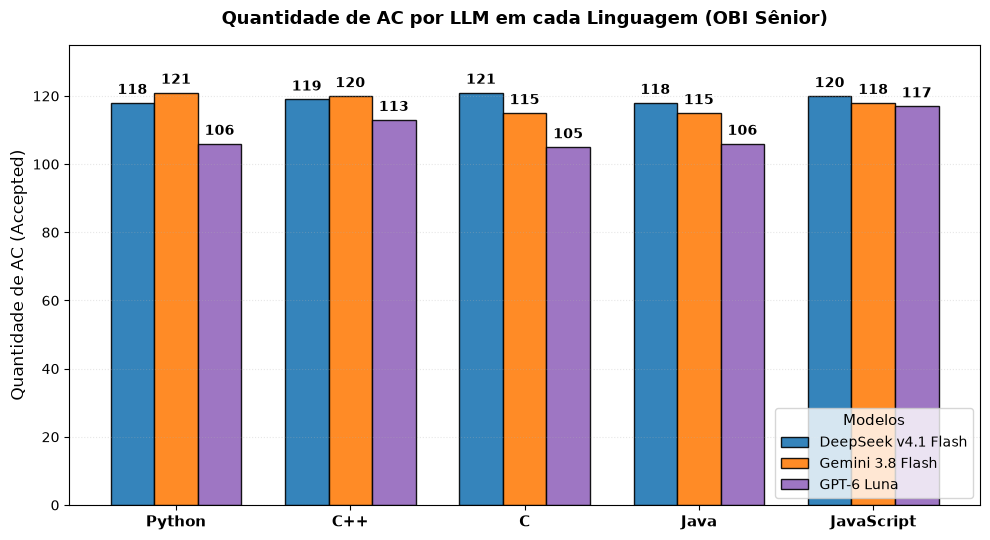

In [25]:
# Gráfico 1: Quantidade de AC por Linguagem (DeepSeek, Gemini, GPT-6 Luna)
main_models = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GPT-6 Luna"]
main_colors = ["#1f77b4", "#ff7f0e", "#9467bd"]

fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(languages))
width = 0.25

for i, (model, color) in enumerate(zip(main_models, main_colors)):
    vals = [results[model][lang] for lang in languages]
    offset = (i - 1) * width
    rects = ax.bar(x + offset, vals, width, label=model, color=color, edgecolor="black", alpha=0.9)
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{int(h)}",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Quantidade de AC (Accepted)", fontsize=12)
ax.set_title("Quantidade de AC por LLM em cada Linguagem (OBI Sênior)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(languages, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.legend(title="Modelos", loc="lower right", fontsize=10, title_fontsize=11)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

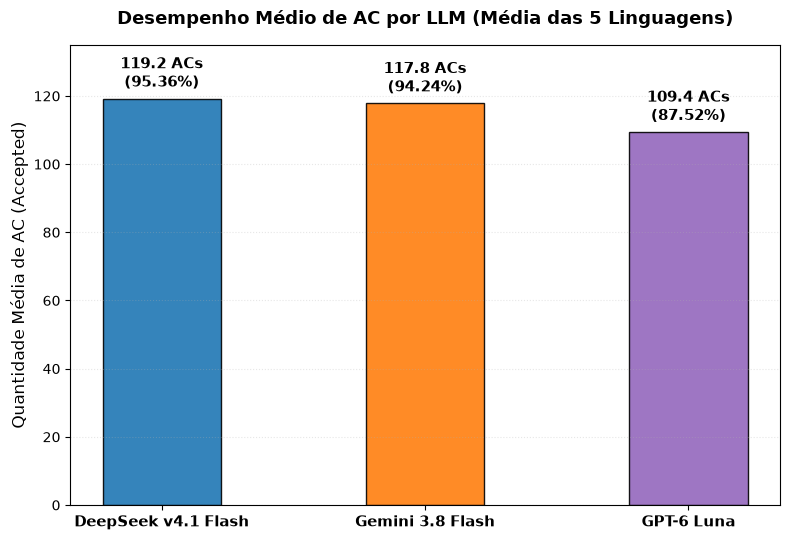

In [26]:
# Gráfico 2: Desempenho Médio de AC por LLM (DeepSeek, Gemini, GPT-6 Luna)
fig, ax = plt.subplots(figsize=(8, 5.5))

means_main = [results[m]["Média"] for m in main_models]
x_main = np.arange(len(main_models))
bars = ax.bar(x_main, means_main, color=main_colors, edgecolor="black", width=0.45, alpha=0.9)

for bar, m_val in zip(bars, means_main):
    pct = (m_val / TOTAL_PROBLEMS) * 100
    ax.annotate(f"{m_val:.1f} ACs\n({pct:.2f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, m_val),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel("Quantidade Média de AC (Accepted)", fontsize=12)
ax.set_title("Desempenho Médio de AC por LLM (Média das 5 Linguagens)", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x_main)
ax.set_xticklabels(main_models, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

## Análise Isolada: GLM 5.3 Flash
---

Nesta seção, o desempenho do **GLM 5.3 Flash** é analisado separadamente, exibindo tanto o gráfico de acertos por linguagem quanto a tabela detalhada com a distribuição de todos os vereditos do judge (`AC`, `WA`, `RE`, `TLE`, `MLE`, `CE`).

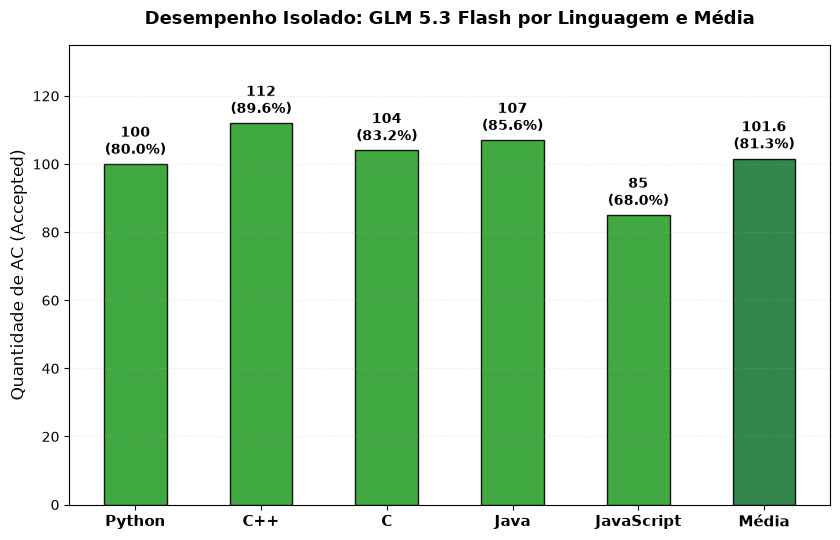

In [27]:
# Gráfico 3: Desempenho Isolado do GLM 5.3 Flash por Linguagem e Média
fig, ax = plt.subplots(figsize=(8.5, 5.5))
glm_cats = languages + ["Média"]
glm_vals = [results["GLM 5.3 Flash"][c] for c in glm_cats]
x_glm = np.arange(len(glm_cats))
glm_colors = ["#2ca02c" if c != "Média" else "#1b7837" for c in glm_cats]

bars_glm = ax.bar(x_glm, glm_vals, color=glm_colors, edgecolor="black", width=0.5, alpha=0.9)
for bar, val in zip(bars_glm, glm_vals):
    pct = (val / TOTAL_PROBLEMS) * 100
    lbl = f"{val:.1f}\n({pct:.1f}%)" if val % 1 != 0 else f"{int(val)}\n({pct:.1f}%)"
    ax.annotate(lbl,
                 xy=(bar.get_x() + bar.get_width() / 2, val),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Quantidade de AC (Accepted)", fontsize=12)
ax.set_title("Desempenho Isolado: GLM 5.3 Flash por Linguagem e Média", fontsize=13, fontweight="bold", pad=15)
ax.set_xticks(x_glm)
ax.set_xticklabels(glm_cats, fontsize=11, fontweight="bold")
ax.set_ylim(0, 135)
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Tabela detalhada dos vereditos do GLM 5.3 Flash por linguagem
df_glm = datas["GLM 5.3 Flash"]
rows_glm = []
for lang in languages:
    sub = df_glm[df_glm['language'] == lang]
    vc = sub['judge_predict'].value_counts().to_dict()
    r = {'Linguagem': lang}
    for v in verdicts:
        r[v] = vc.get(v, 0)
    r['Total'] = len(sub)
    r['Taxa AC (%)'] = f"{(r['AC'] / TOTAL_PROBLEMS) * 100:.2f}%"
    rows_glm.append(r)

tot_glm = {'Linguagem': 'Total Geral'}
vc_all = df_glm['judge_predict'].value_counts().to_dict()
for v in verdicts:
    tot_glm[v] = vc_all.get(v, 0)
tot_glm['Total'] = len(df_glm)
tot_glm['Taxa AC (%)'] = f"{(tot_glm['AC'] / len(df_glm)) * 100:.2f}%"
rows_glm.append(tot_glm)
df_glm_detail = pd.DataFrame(rows_glm)

print("Detalhamento dos Vereditos do Judge para o GLM 5.3 Flash por Linguagem:")
display(df_glm_detail)

Detalhamento dos Vereditos do Judge para o GLM 5.3 Flash por Linguagem:


,Linguagem,AC,WA,RE,TLE,MLE,CE,Total,Taxa AC (%)
0,Python,100,10,2,0,0,13,125,80.00%
1,C++,112,9,0,0,0,4,125,89.60%
2,C,104,7,0,2,0,12,125,83.20%
3,Java,107,9,2,2,0,5,125,85.60%
4,JavaScript,85,10,24,0,0,6,125,68.00%
5,Total Geral,508,45,28,4,0,40,625,81.28%
